# Module 4 - Evaluation Metrics for Classification

## Topics

- **Accuracy**, and why a dummy model that predicts "no churn" for everybody is a useful sanity check
- **Confusion matrix**: the four types of correct decisions and errors a binary classifier makes
- **Precision and Recall**: metrics that look at the positive class specifically
- **ROC curves**: true positive rate and false positive rate across all possible thresholds, with random and ideal models as reference points
- **ROC AUC**: the area under the ROC curve, a single number for curve quality
- **Cross-validation**: a more reliable way to measure model quality and tune parameters

## Recap and Setup

We will basically be continuing off with the same scenario and code from module 3

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pprint import pprint

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

# Force numbers to display as decimals, not scientific notation
np.set_printoptions(suppress=True)

RANDOM_SEED = 1

df = pd.read_csv('churn_data.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Data preparation

In [2]:
# Standardize column names
df.columns = df.columns.str.lower().str.replace(' ', '_')

# Standardize categorical values
categorical_columns = list(df.dtypes[df.dtypes == 'string'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.head()

,customerid,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,...,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn
0,7590-vhveg,female,0,yes,no,1,no,no_phone_service,dsl,no,...,no,no,no,no,month-to-month,yes,electronic_check,29.85,29.85,no
1,5575-gnvde,male,0,no,no,34,yes,no,dsl,yes,...,yes,no,no,no,one_year,no,mailed_check,56.95,1889.5,no
2,3668-qpybk,male,0,no,no,2,yes,no,dsl,yes,...,no,no,no,no,month-to-month,yes,mailed_check,53.85,108.15,yes
3,7795-cfocw,male,0,no,no,45,no,no_phone_service,dsl,yes,...,yes,yes,no,no,one_year,no,bank_transfer_(automatic),42.30,1840.75,no
4,9237-hqitu,female,0,no,no,2,yes,no,fiber_optic,no,...,no,no,no,no,month-to-month,yes,electronic_check,70.70,151.65,yes


In [3]:
# Handle missing values
df['totalcharges'] = pd.to_numeric(df['totalcharges'], errors='coerce')

df['totalcharges'].isnull().sum()

np.int64(11)

In [4]:
df['totalcharges'] = df['totalcharges'].fillna(0)

df['totalcharges'].isnull().sum()

np.int64(0)

In [5]:
# Convert target to numeric
df['churn'] = (df['churn'] == 'yes').astype(int)

df['churn'].unique()


array([0, 1])

In [6]:
# Split the data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)

print(df_full_train.shape)
print(df_test.shape)

(5634, 21)
(1409, 21)


In [7]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(df_train.shape)
print(df_val.shape)

(4225, 21)
(1409, 21)


In [8]:
# Reset indexes
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [9]:
# Extract target variable
y_train = df_train['churn'].values
y_val = df_val['churn'].values
y_test = df_test['churn'].values

print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(4225,)
(1409,)
(1409,)


In [10]:
# Drop target from feature matrixes
del df_train['churn']
del df_val['churn']
del df_test['churn']

print(df_train.columns)
print(df_val.columns)
print(df_test.columns)

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges'],
      dtype='str')
Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges'],
      dtype='str')
Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'co

In [11]:
features = df.columns.drop(['customerid', 'churn'])

numerical = df[features].select_dtypes(include='number').columns.tolist()
categorical = df[features].select_dtypes(exclude='number').columns.tolist()

print('Numerical features:')
print(numerical)
print()
print('Categorical features:')
print(categorical)

Numerical features:
['seniorcitizen', 'tenure', 'monthlycharges', 'totalcharges']

Categorical features:
['gender', 'partner', 'dependents', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']


In [12]:
# One-hot encoding
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')

X_train = dv.fit_transform(train_dict)
X_train

array([[   0.  ,    0.  ,    1.  , ...,    1.  ,   72.  , 8425.15],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,   10.  , 1021.55],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    5.  ,  413.65],
       ...,
       [   1.  ,    0.  ,    0.  , ...,    1.  ,    2.  ,  190.05],
       [   0.  ,    0.  ,    1.  , ...,    0.  ,   27.  ,  761.95],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    9.  ,  751.65]],
      shape=(4225, 45))

In [13]:
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=one_year',
       'contract=two_year', 'dependents=no', 'dependents=yes',
       'deviceprotection=no', 'deviceprotection=no_internet_service',
       'deviceprotection=yes', 'gender=female', 'gender=male',
       'internetservice=dsl', 'internetservice=fiber_optic',
       'internetservice=no', 'monthlycharges', 'multiplelines=no',
       'multiplelines=no_phone_service', 'multiplelines=yes',
       'onlinebackup=no', 'onlinebackup=no_internet_service',
       'onlinebackup=yes', 'onlinesecurity=no',
       'onlinesecurity=no_internet_service', 'onlinesecurity=yes',
       'paperlessbilling=no', 'paperlessbilling=yes', 'partner=no',
       'partner=yes', 'paymentmethod=bank_transfer_(automatic)',
       'paymentmethod=credit_card_(automatic)',
       'paymentmethod=electronic_check', 'paymentmethod=mailed_check',
       'phoneservice=no', 'phoneservice=yes', 'seniorcitizen',
       'streamingmovies=no', 'streamingmovies=no_internet_service',

In [14]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')

X_val = dv.transform(val_dict)
X_val

array([[   0.  ,    0.  ,    1.  , ...,    1.  ,   71.  , 4973.4 ],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    1.  ,   20.75],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    1.  ,   20.35],
       ...,
       [   1.  ,    0.  ,    0.  , ...,    1.  ,   18.  , 1058.1 ],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    1.  ,   93.3 ],
       [   1.  ,    0.  ,    0.  , ...,    0.  ,    3.  ,  292.85]],
      shape=(1409, 45))

### Model training

In [15]:
model = LogisticRegression(random_state=RANDOM_SEED)

model.fit(X_train, y_train)

/home/red/ml-zoomcamp-2026/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

### Generate predictions and evaluate

In [16]:
# Generate predictions
y_pred = model.predict_proba(X_val)[:, 1]
y_pred

array([0.00900149, 0.20409034, 0.21172505, ..., 0.13635079, 0.79942379,
       0.83708596], shape=(1409,))

In [17]:
# Evaluate performance
churn_decision = (y_pred >= 0.5)

(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

## Accuracy and Dummy Model

### Computation

Accuracy essentially answers how many predictions we got right out of the total:

`accuracy = correct predictions / total predictions`

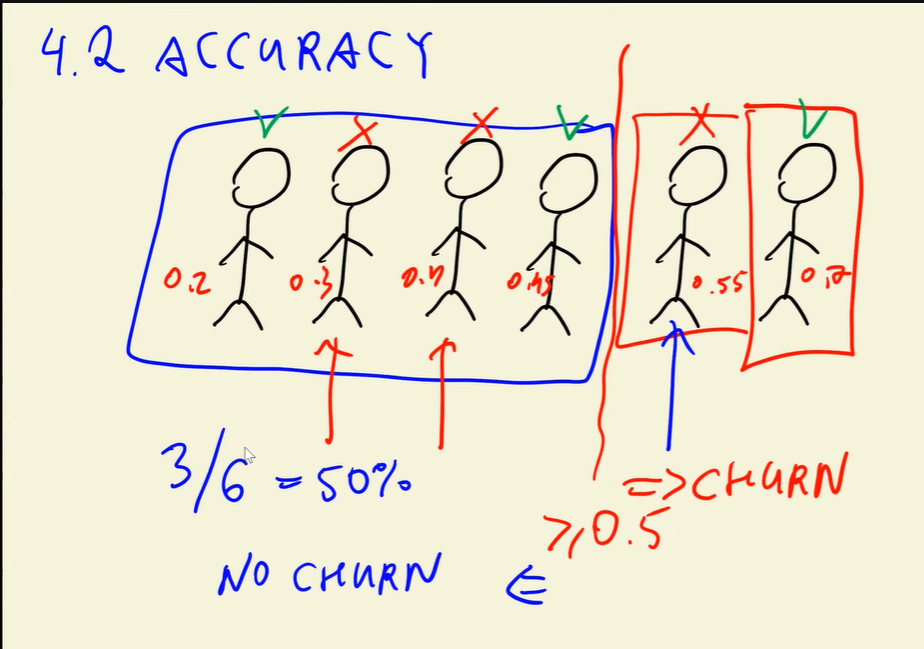

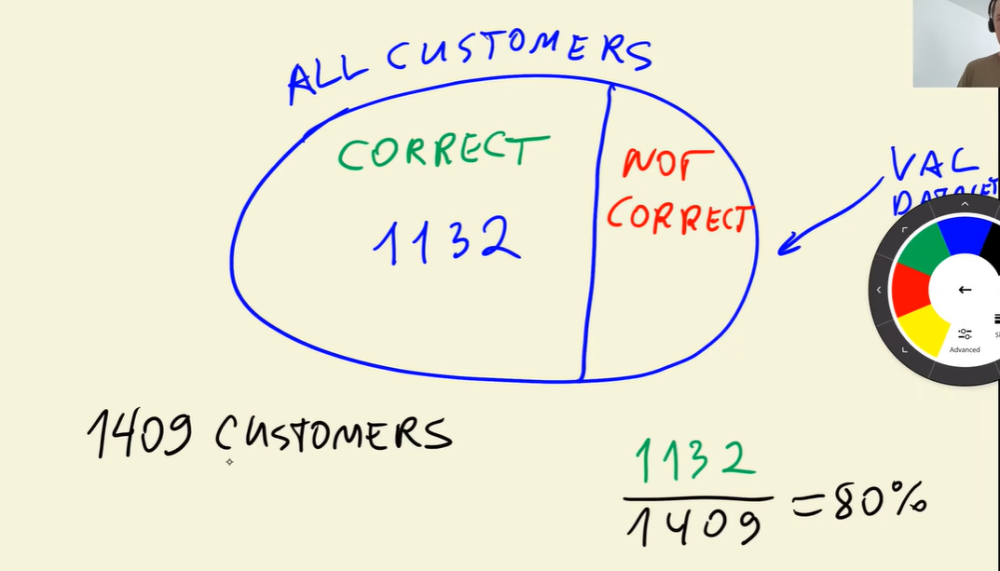

In [18]:
total = len(y_val)
total

1409

In [19]:
correct = (y_val == churn_decision).sum()
correct

np.int64(1132)

In [20]:
accuracy = correct / total
accuracy.round(4)

np.float64(0.8034)

### Is our threshold good?

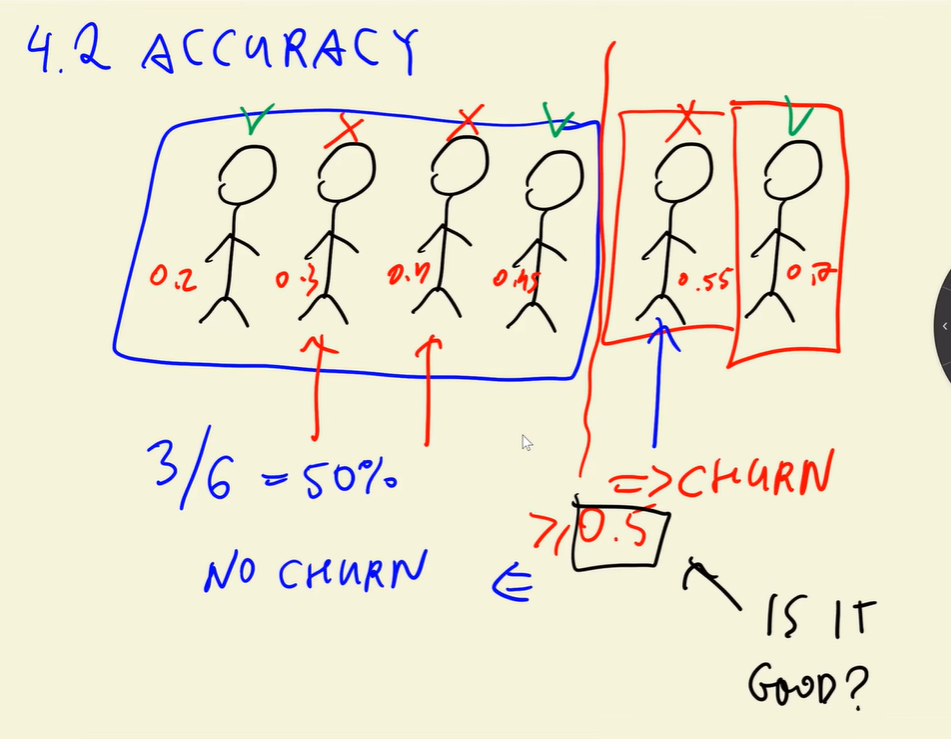

In [21]:
thresholds = np.linspace(0, 1, 21)
thresholds

array([0.  , 0.05, 0.1 , 0.15, 0.2 , 0.25, 0.3 , 0.35, 0.4 , 0.45, 0.5 ,
       0.55, 0.6 , 0.65, 0.7 , 0.75, 0.8 , 0.85, 0.9 , 0.95, 1.  ])

In [22]:
thresholds = np.linspace(0, 1, 21)

scores = []

for threshold in thresholds:
    churn_decision = (y_pred >= threshold)
    accuracy = (y_val == churn_decision).mean()
    scores.append(accuracy)

    print(f'Threshold: {round(float(threshold), 4)},  Accuracy: {float(accuracy)}')


Threshold: 0.0,  Accuracy: 0.2739531582682754
Threshold: 0.05,  Accuracy: 0.5088715400993612
Threshold: 0.1,  Accuracy: 0.5911994322214337
Threshold: 0.15,  Accuracy: 0.6671398154719659
Threshold: 0.2,  Accuracy: 0.7097232079489
Threshold: 0.25,  Accuracy: 0.7374024130589071
Threshold: 0.3,  Accuracy: 0.7601135557132718
Threshold: 0.35,  Accuracy: 0.7721788502484032
Threshold: 0.4,  Accuracy: 0.7849538679914834
Threshold: 0.45,  Accuracy: 0.7934705464868701
Threshold: 0.5,  Accuracy: 0.8034066713981547
Threshold: 0.55,  Accuracy: 0.801277501774308
Threshold: 0.6,  Accuracy: 0.794889992902768
Threshold: 0.65,  Accuracy: 0.7863733144073811
Threshold: 0.7,  Accuracy: 0.7650816181689141
Threshold: 0.75,  Accuracy: 0.7444996451383961
Threshold: 0.8,  Accuracy: 0.7345635202271115
Threshold: 0.85,  Accuracy: 0.7260468417317246
Threshold: 0.9,  Accuracy: 0.7260468417317246
Threshold: 0.95,  Accuracy: 0.7260468417317246
Threshold: 1.0,  Accuracy: 0.7260468417317246


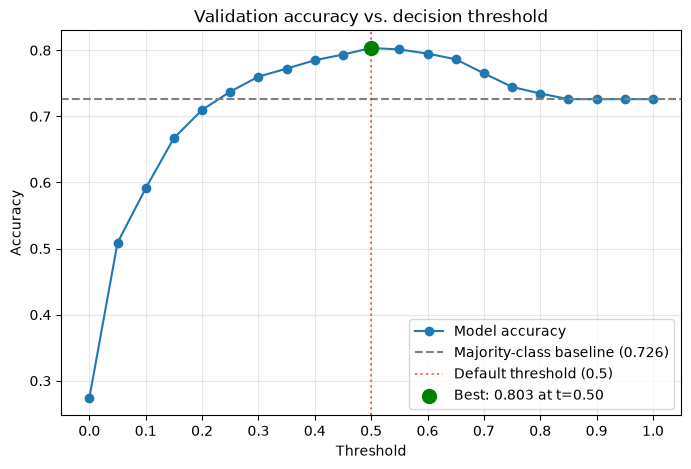

In [23]:
best_idx = int(np.argmax(scores))
best_t, best_acc = thresholds[best_idx], scores[best_idx]
baseline = max(y_val.mean(), 1 - y_val.mean())  # always predict the majority class

plt.figure(figsize=(8, 5))
plt.plot(thresholds, scores, marker='o', label='Model accuracy')
plt.axhline(baseline, color='gray', linestyle='--', label=f'Majority-class baseline ({baseline:.3f})')
plt.axvline(0.5, color='red', linestyle=':', alpha=0.6, label='Default threshold (0.5)')
plt.scatter([best_t], [best_acc], color='green', zorder=5, s=100,
            label=f'Best: {best_acc:.3f} at t={best_t:.2f}')

plt.xlabel('Threshold')
plt.ylabel('Accuracy')
plt.title('Validation accuracy vs. decision threshold')
plt.xticks(np.linspace(0, 1, 11))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### Using sklearn's built-in accuracy function

In [24]:
from sklearn.metrics import accuracy_score

for threshold in thresholds:
    churn_decision = (y_pred >= threshold)
    accuracy = accuracy_score(y_val, churn_decision)

    print(f'Threshold: {round(float(threshold), 4)},  Accuracy: {float(accuracy)}')

Threshold: 0.0,  Accuracy: 0.2739531582682754
Threshold: 0.05,  Accuracy: 0.5088715400993612
Threshold: 0.1,  Accuracy: 0.5911994322214337
Threshold: 0.15,  Accuracy: 0.6671398154719659
Threshold: 0.2,  Accuracy: 0.7097232079489
Threshold: 0.25,  Accuracy: 0.7374024130589071
Threshold: 0.3,  Accuracy: 0.7601135557132718
Threshold: 0.35,  Accuracy: 0.7721788502484032
Threshold: 0.4,  Accuracy: 0.7849538679914834
Threshold: 0.45,  Accuracy: 0.7934705464868701
Threshold: 0.5,  Accuracy: 0.8034066713981547
Threshold: 0.55,  Accuracy: 0.801277501774308
Threshold: 0.6,  Accuracy: 0.794889992902768
Threshold: 0.65,  Accuracy: 0.7863733144073811
Threshold: 0.7,  Accuracy: 0.7650816181689141
Threshold: 0.75,  Accuracy: 0.7444996451383961
Threshold: 0.8,  Accuracy: 0.7345635202271115
Threshold: 0.85,  Accuracy: 0.7260468417317246
Threshold: 0.9,  Accuracy: 0.7260468417317246
Threshold: 0.95,  Accuracy: 0.7260468417317246
Threshold: 1.0,  Accuracy: 0.7260468417317246


### Dummy model

What if we predict that all customers will not churn?

In [25]:
from collections import Counter

Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

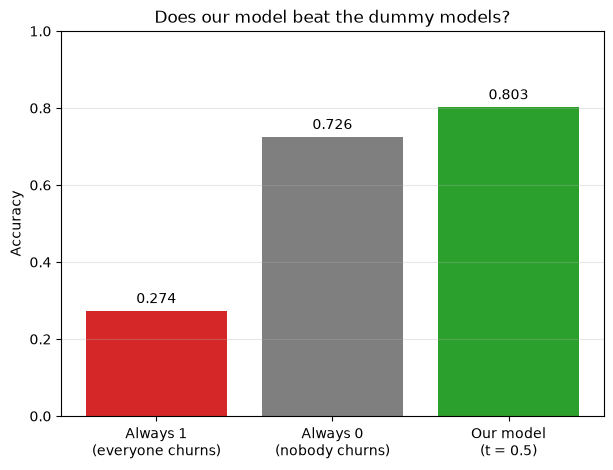

In [26]:
always_1 = np.ones(len(y_val), dtype=bool)
always_0 = np.zeros(len(y_val), dtype=bool)

acc_always_1 = (y_val == always_1).mean()   # equals y_val.mean(), the churn rate
acc_always_0 = (y_val == always_0).mean()   # equals 1 - y_val.mean()
acc_model = (y_val == (y_pred >= 0.5)).mean()

labels = ['Always 1\n(everyone churns)', 'Always 0\n(nobody churns)', 'Our model\n(t = 0.5)']
values = [acc_always_1, acc_always_0, acc_model]
colors = ['tab:red', 'tab:gray', 'tab:green']

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, values, color=colors)
plt.bar_label(bars, fmt='%.3f', padding=3)

plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.title('Does our model beat the dummy models?')
plt.grid(axis='y', alpha=0.3)
plt.show()


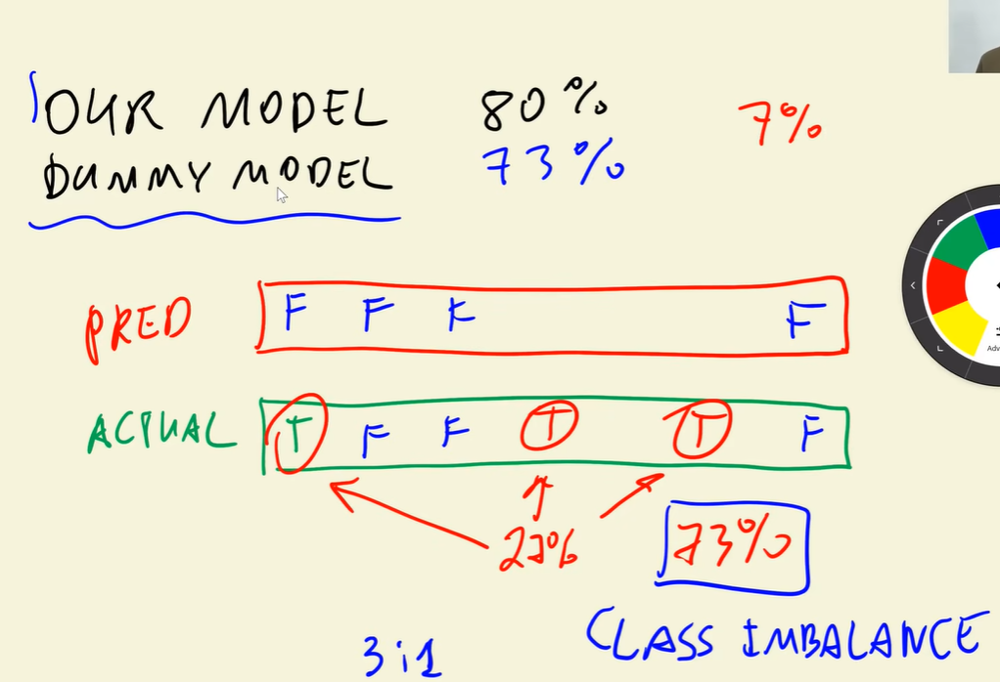

**Key takeaway:** Accuracy is not a good metric if there is class imbalance

## Confusion Matrix

### Concepts

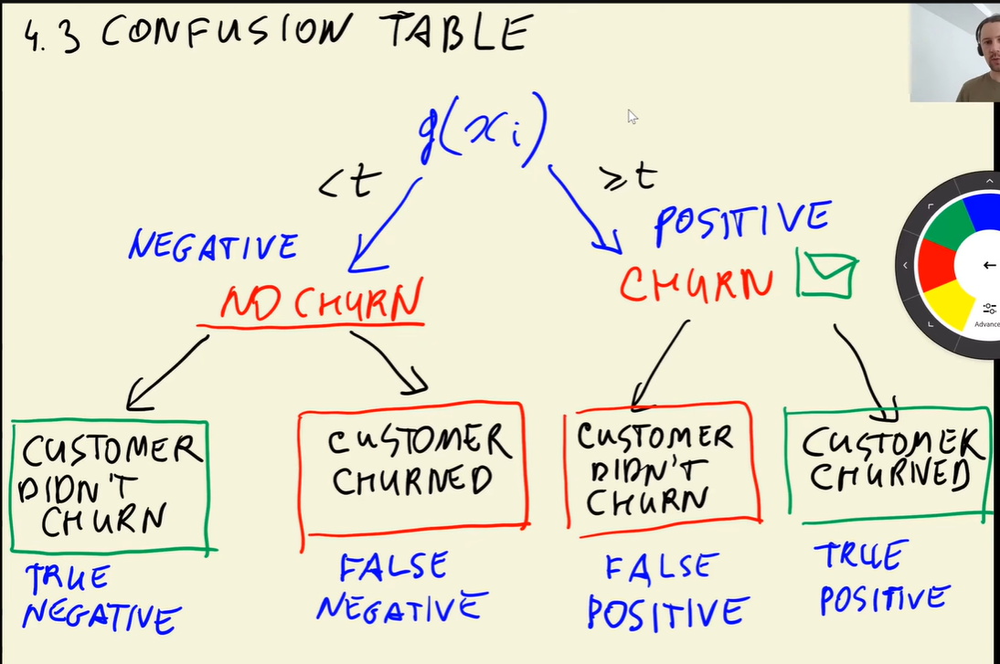

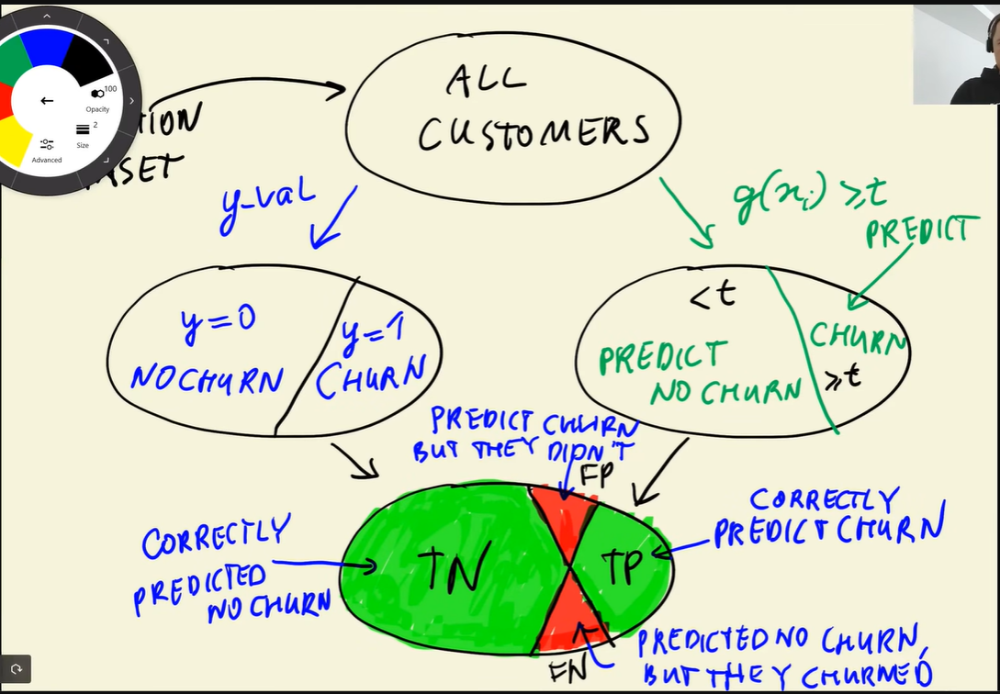

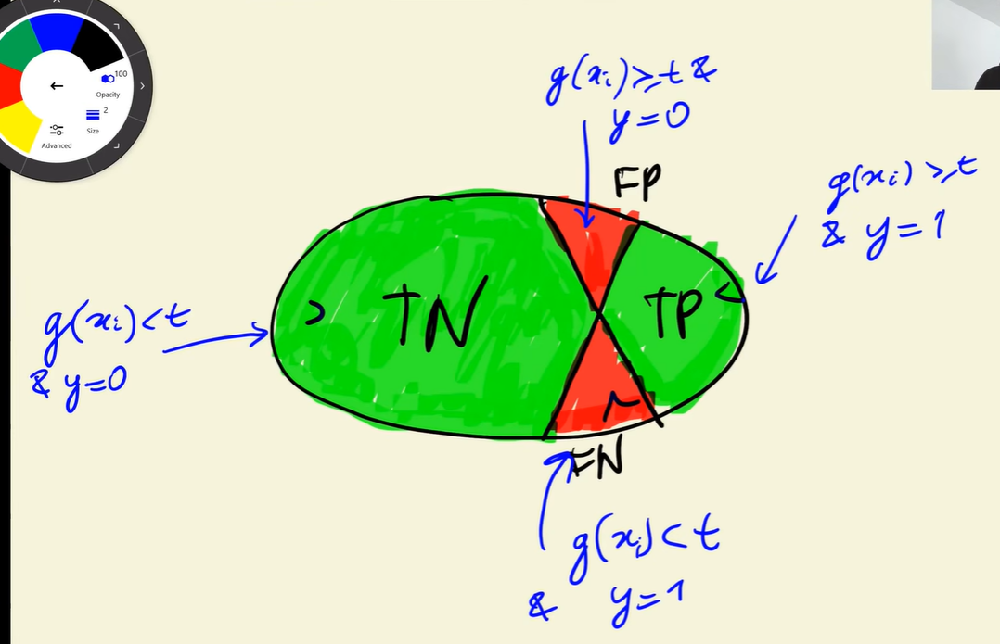

### Implementation

In [27]:
actual_positive = (y_val == 1)
actual_positive

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [28]:
actual_negative = (y_val == 0)
actual_negative

array([ True,  True,  True, ...,  True, False, False], shape=(1409,))

In [29]:
threshold = 0.5

predict_positive = (y_pred >= threshold)
predict_positive

array([False, False, False, ..., False,  True,  True], shape=(1409,))

In [30]:
predict_negative = (y_pred < threshold)
predict_negative

array([ True,  True,  True, ...,  True, False, False], shape=(1409,))

In [31]:
true_positives = (predict_positive & actual_positive).sum()
true_positives

np.int64(210)

In [32]:
true_negatives = (predict_negative & actual_negative).sum()
true_negatives

np.int64(922)

In [33]:
false_positives = (predict_positive & actual_negative).sum()
false_positives

np.int64(101)

In [34]:
false_negatives = (predict_negative & actual_positive).sum()
false_negatives

np.int64(176)

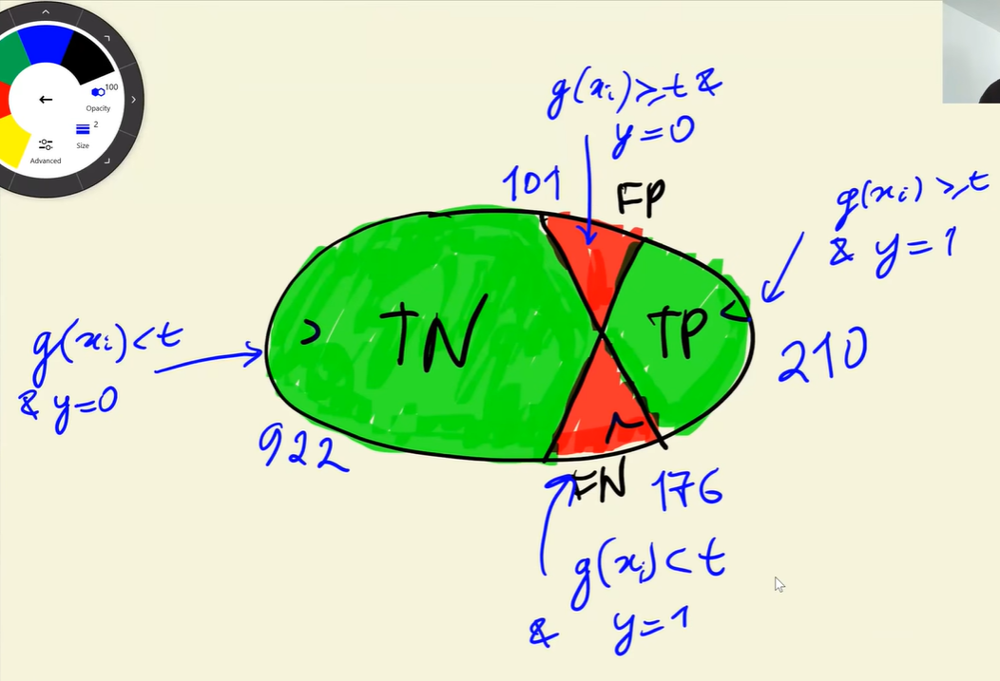

### Actual confusion matrix

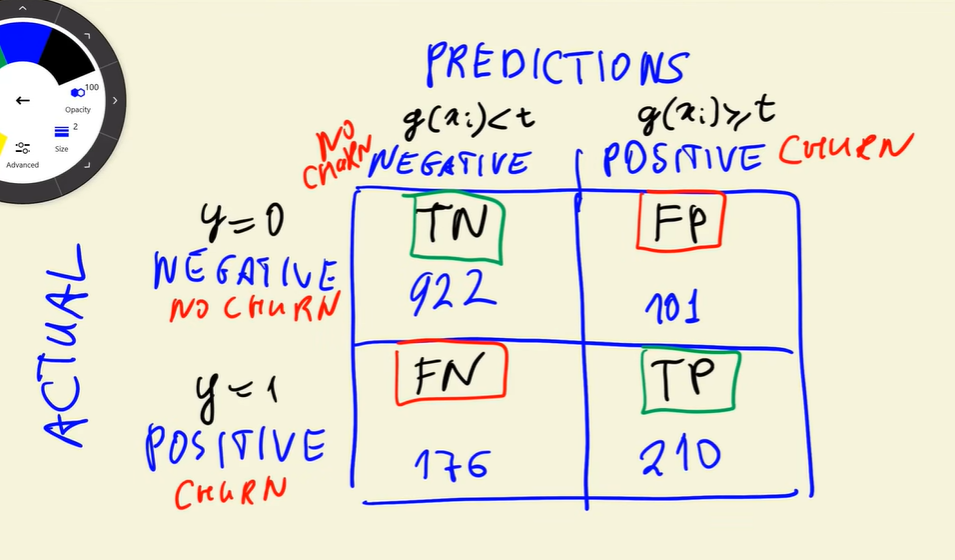

### NumPy implementation

In [35]:
confusion_matrix_np = np.array([
    [true_negatives, false_positives],
    [false_negatives, true_positives]
])

confusion_matrix_np

array([[922, 101],
       [176, 210]])

### Normalizing the confusion matrix

In [36]:
(confusion_matrix_np / confusion_matrix_np.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

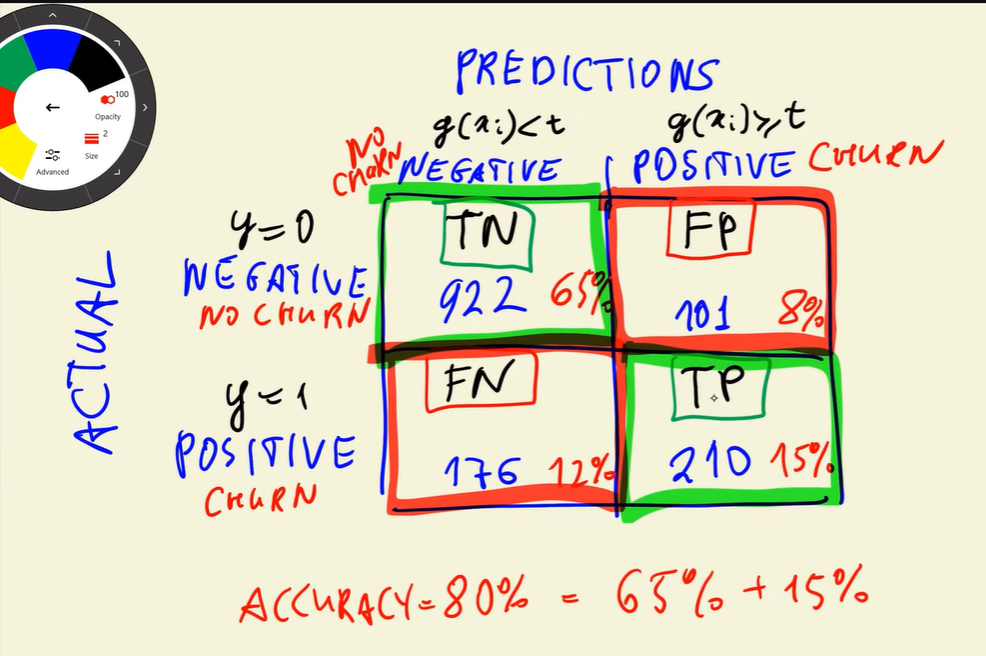

## Precision and Recall

In [37]:
tp = true_positives
tn = true_negatives
fp = false_positives
fn = false_negatives

### Another way to compute accuracy

In [38]:
# Same number from previous lessons
(tp + tn) / (tp + tn + fp + fn)

np.float64(0.8034066713981547)

### Precision

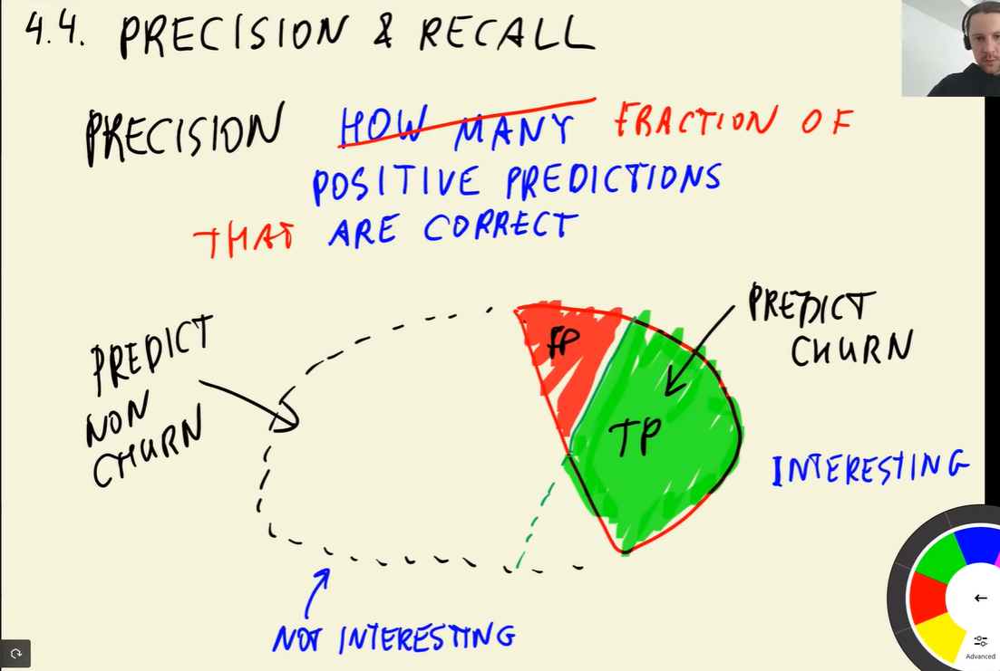

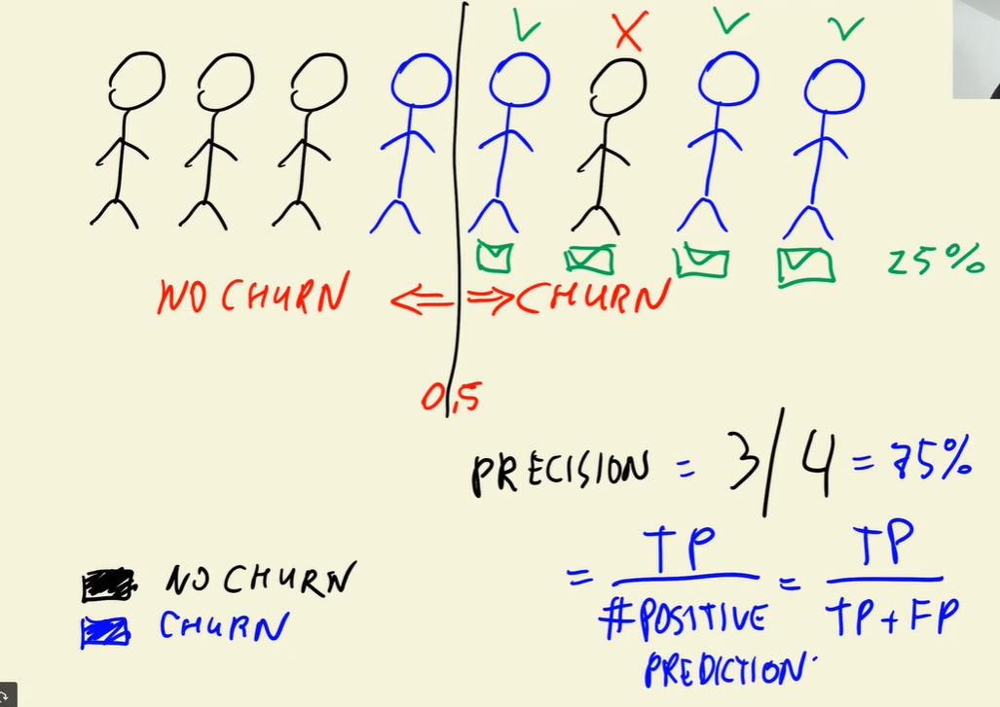

In [39]:
precision = tp / (tp + fp)
precision 

np.float64(0.6752411575562701)

### Recall

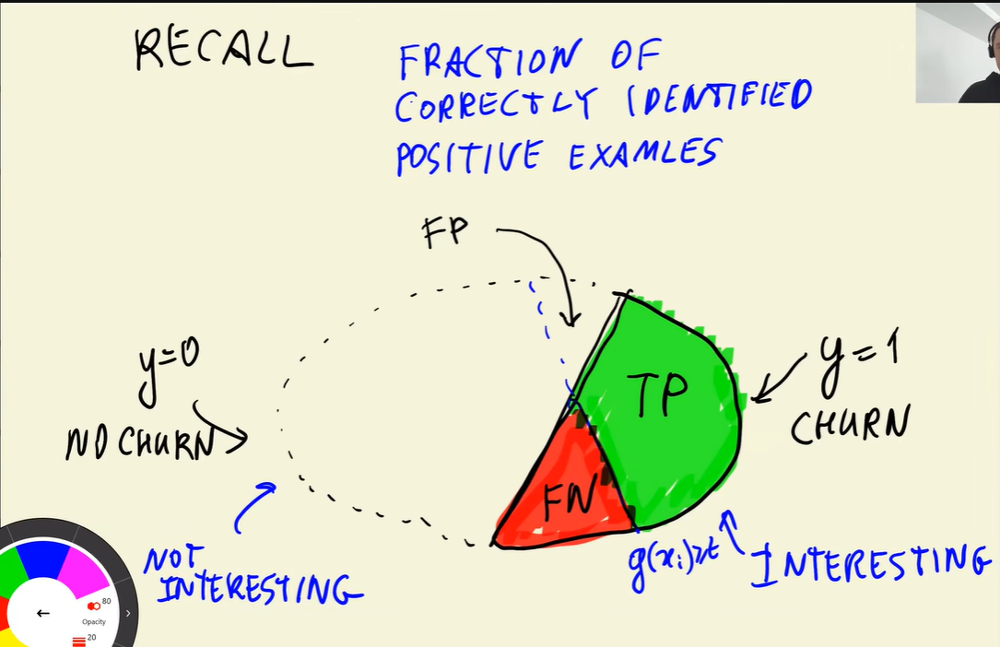

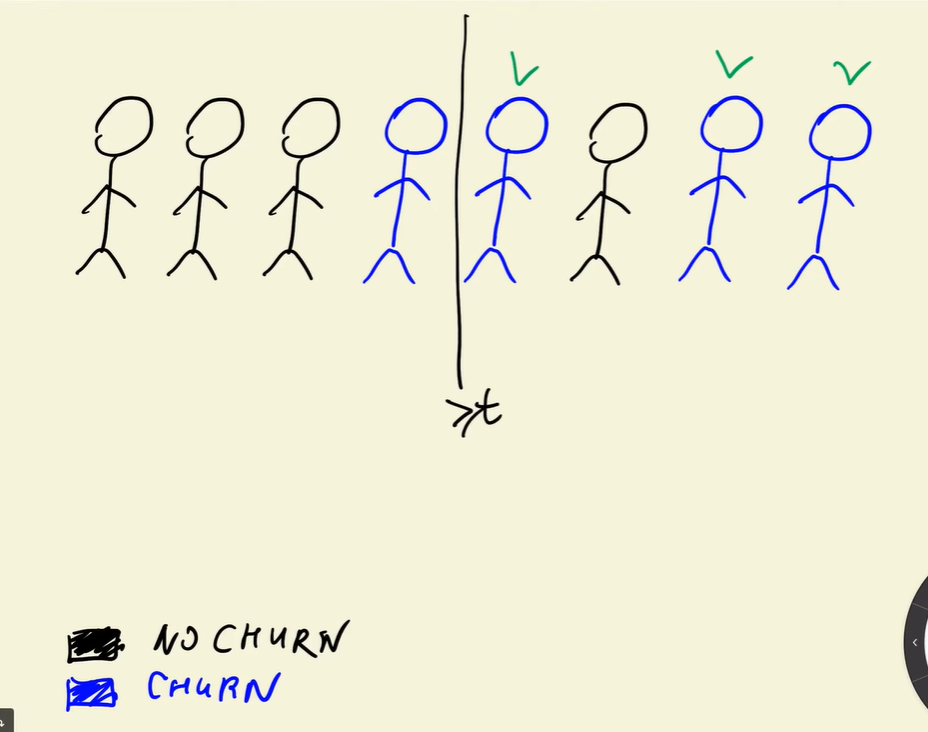

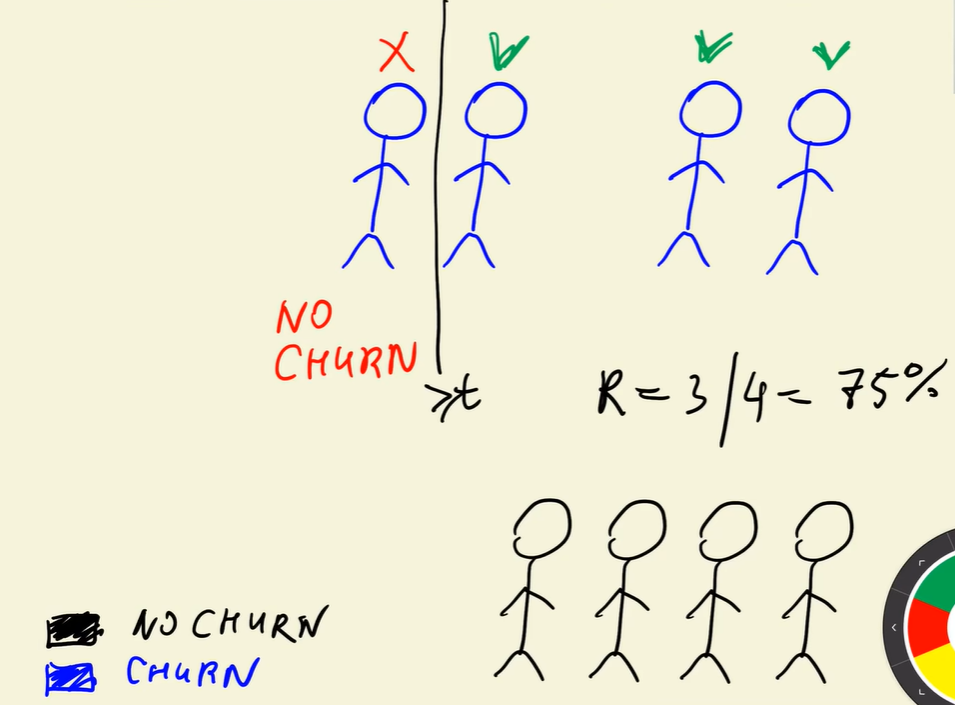

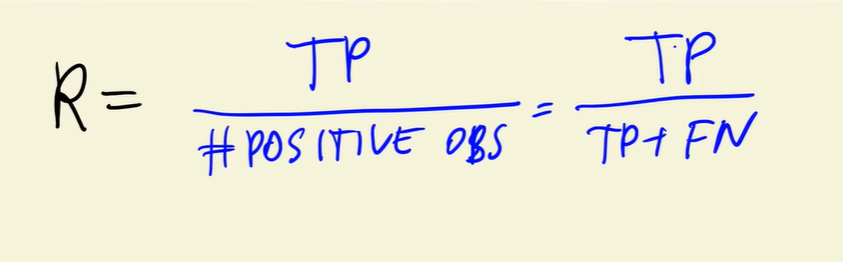

In [40]:
recall = tp / (tp + fn)
recall

np.float64(0.5440414507772021)

### Why accuracy is misleading for churn example

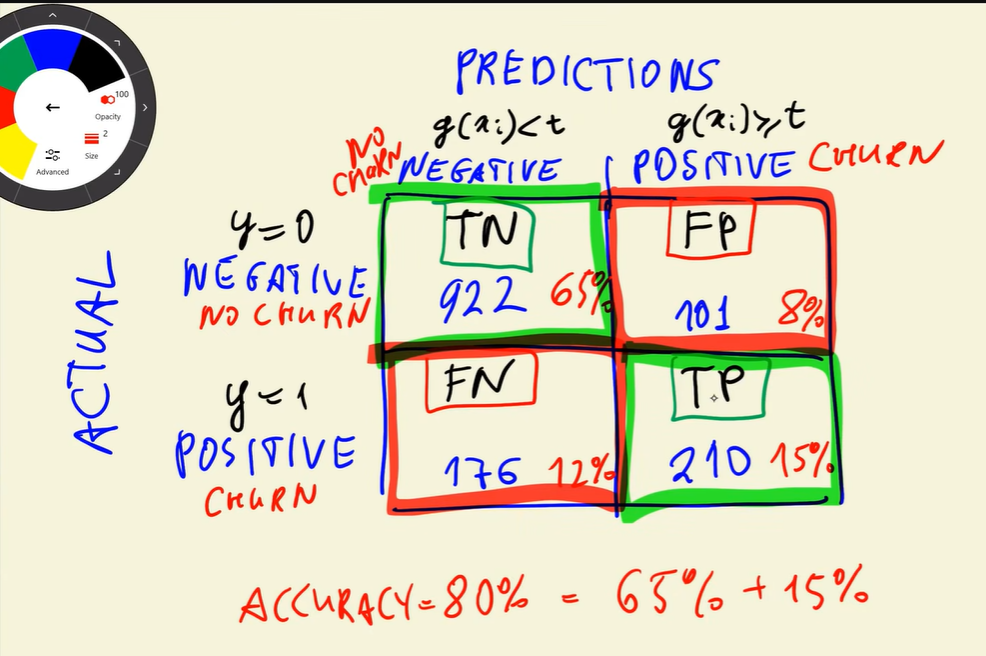

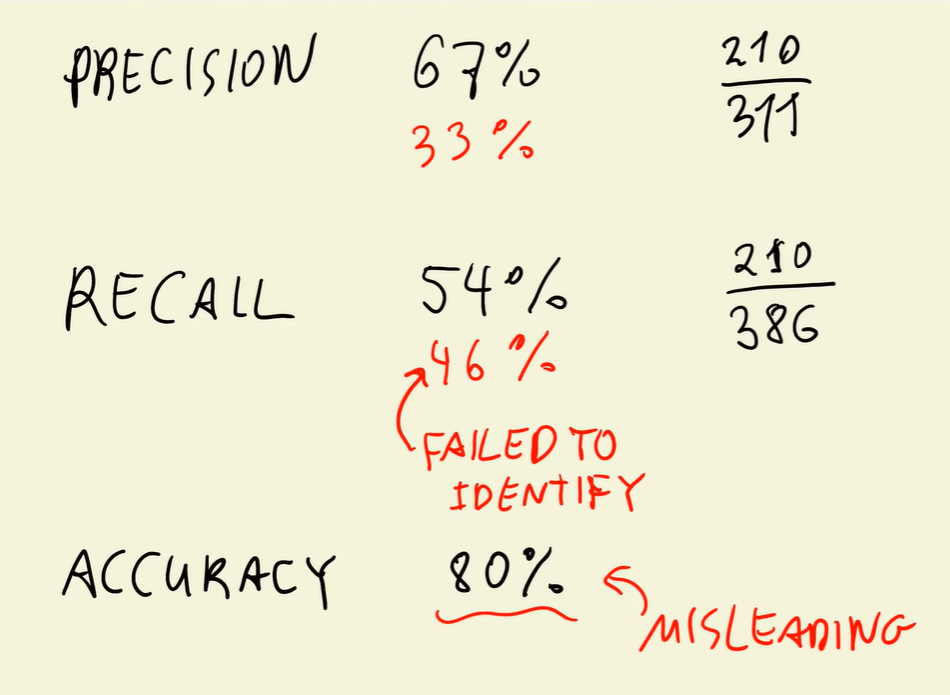

Because of class imbalance, accuracy is misleading because it looks like our model is performing relatively well, but if we look at precision and recall, we see that the performance is lower

### Recap

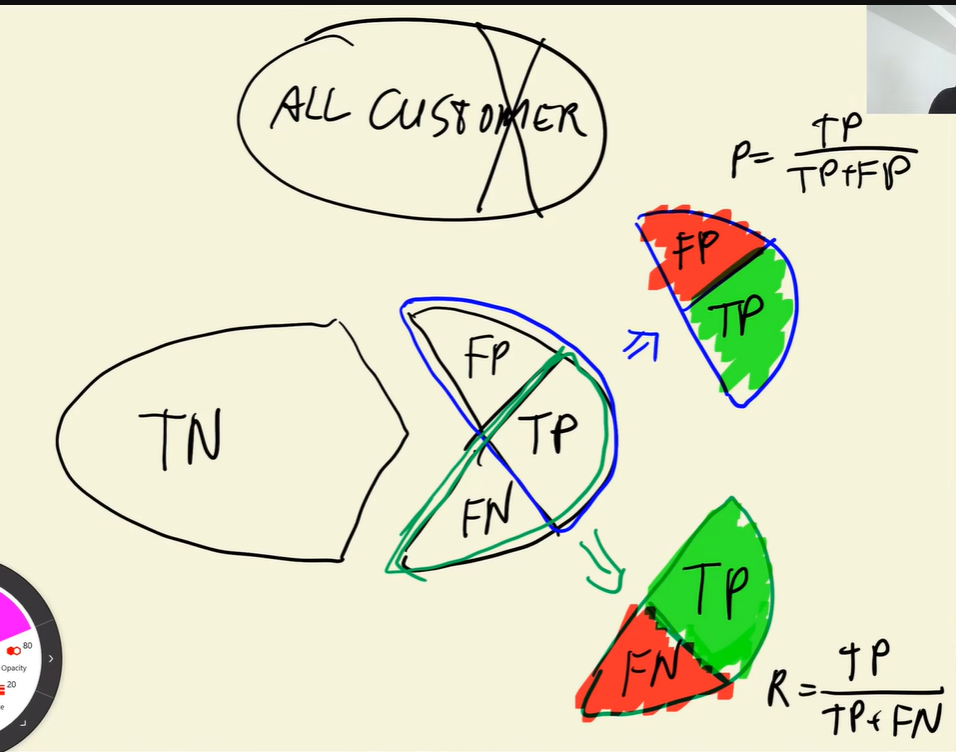

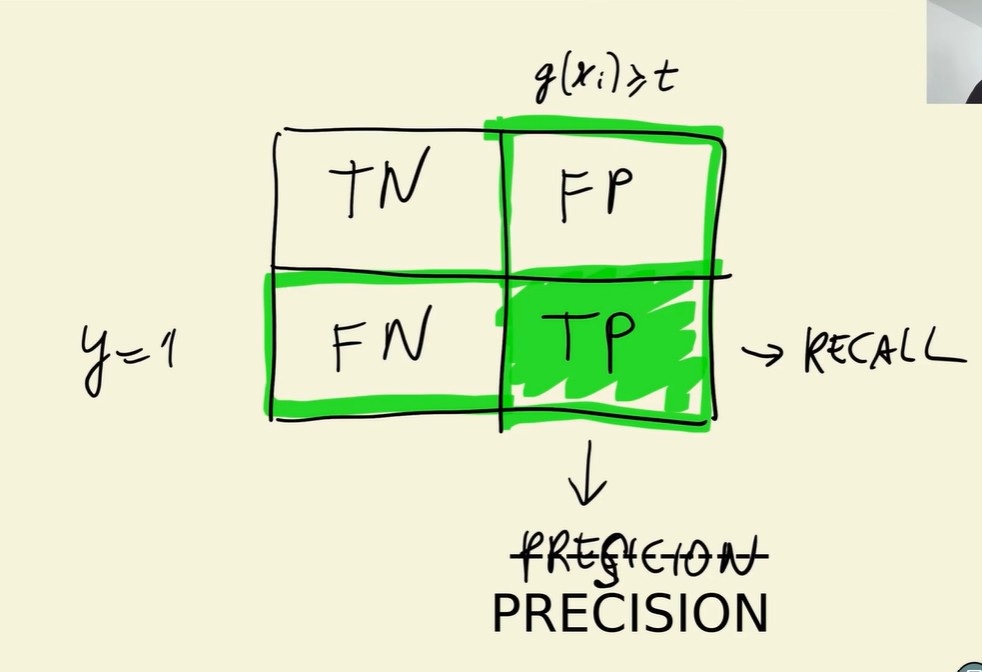

## ROC Curves

### Overview

**ROC** - Receiver Operating Characteristic

Basically, this is a metric for describing the performance of a binary classification model

Originally, ROC curves were used for evaluating the strength of radar detectors in WW2

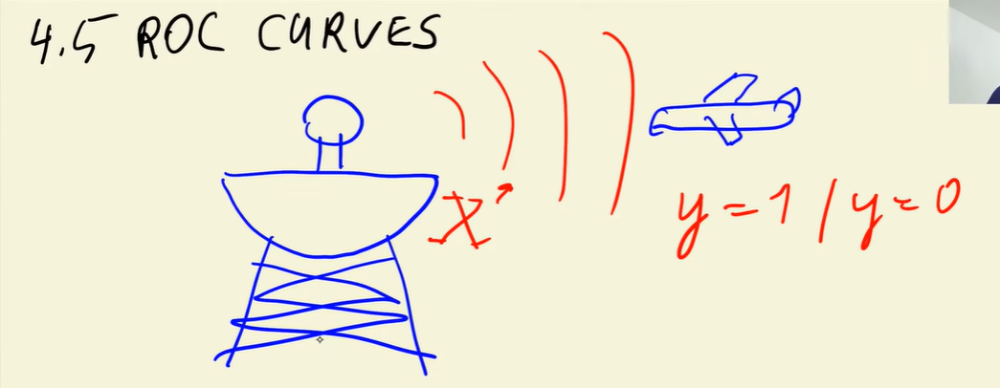

### TPR and FPR

These are the two most important metrics for ROC curves:

- True Positive Rate (TPR)
- False Positive Rate (FPR)

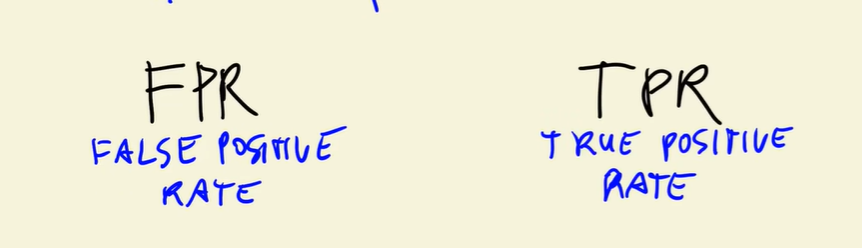

These are computed from the confusion matrix:

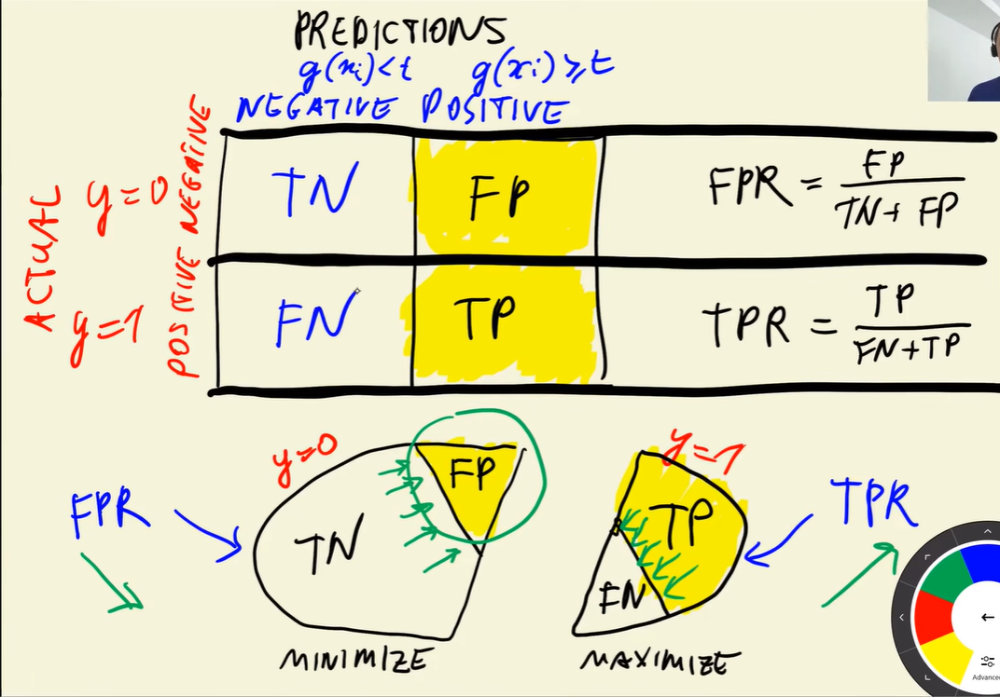

In [41]:
tpr = tp / (tp + fn)
tpr

np.float64(0.5440414507772021)

In [42]:
# TPR is always the same as Recall
recall

np.float64(0.5440414507772021)

In [43]:
fpr = fp / (fp + tn)
fpr

np.float64(0.09872922776148582)

When measuring TPR and FPR, we don't want to compute these values for just one threshold.

Ideally, we want to compute the TPR and FPR for as many thresholds as possible. 

Each threshold gives one (FPR, TPR) point, and together they form the ROC curve.

In [44]:
def tpr_fpr_dataframe(y_val, y_pred):
    thresholds = np.linspace(0, 1, 101)
    scores = []

    for threshold in thresholds:

        # Create the confusion matrix
        actual_positive = (y_val == 1)
        actual_negative = (y_val == 0)

        predict_positive = (y_pred >= threshold)
        predict_negative = (y_pred < threshold)

        tp = (predict_positive & actual_positive).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()

        # Record the TP, TN, FP, FN values for current threshold
        scores.append((threshold, tp, fp, fn, tn))

    # Create the df
    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    # Compute the TPR and FPR for current threshold
    df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [45]:
df_scores = tpr_fpr_dataframe(y_val, y_pred)

df_scores[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,366,556,20,467,0.948187,0.543500
20,0.2,333,356,53,667,0.862694,0.347996
30,0.3,284,236,102,787,0.735751,0.230694
40,0.4,249,166,137,857,0.645078,0.162268
50,0.5,210,101,176,922,0.544041,0.098729
60,0.6,150,53,236,970,0.388601,0.051808
70,0.7,75,20,311,1003,0.194301,0.019550
80,0.8,13,1,373,1022,0.033679,0.000978
90,0.9,0,0,386,1023,0.000000,0.000000


In [46]:
def plot_tpr_fpr(df_scores, ref_threshold=0.5, title='TPR and FPR across thresholds'):
    plt.figure(figsize=(7, 5))
    plt.plot(df_scores['threshold'], df_scores['tpr'], label='TPR')
    plt.plot(df_scores['threshold'], df_scores['fpr'], label='FPR')

    if ref_threshold is not None:
        plt.axvline(ref_threshold, color='gray', linestyle='--', linewidth=1,
                    label=f'threshold = {ref_threshold}')

    plt.xlabel('Threshold')
    plt.ylabel('Rate')
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

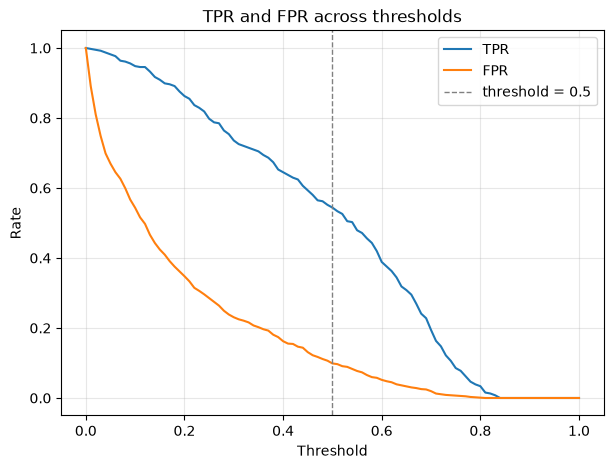

In [47]:
plot_tpr_fpr(df_scores)

### Random model

We create a random model as a baseline to compare against: it simply predicts churn at random, so it has no real predictive power, and any useful model should perform better than it.

In [48]:
np.random.seed(RANDOM_SEED)

y_rand = np.random.uniform(0, 1, size=len(y_val)).round(3)
y_rand

array([0.417, 0.72 , 0.   , ..., 0.774, 0.334, 0.089], shape=(1409,))

Compute the accuracy of our random model:

In [49]:
((y_rand >= 0.5) == y_val).mean()

np.float64(0.5017743080198722)

Plot the random model's ROC curve

In [50]:
df_rand = tpr_fpr_dataframe(y_val, y_rand)

df_rand[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,347,923,39,100,0.898964,0.902248
20,0.2,307,822,79,201,0.795337,0.803519
30,0.3,276,724,110,299,0.715026,0.707722
40,0.4,237,624,149,399,0.613990,0.609971
50,0.5,203,519,183,504,0.525907,0.507331
60,0.6,162,410,224,613,0.419689,0.400782
70,0.7,120,302,266,721,0.310881,0.295210
80,0.8,79,207,307,816,0.204663,0.202346
90,0.9,40,101,346,922,0.103627,0.098729


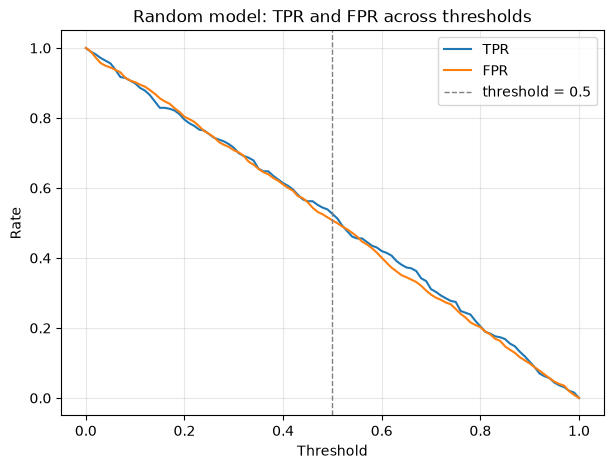

In [51]:
plot_tpr_fpr(df_rand, title='Random model: TPR and FPR across thresholds')

### Ideal model

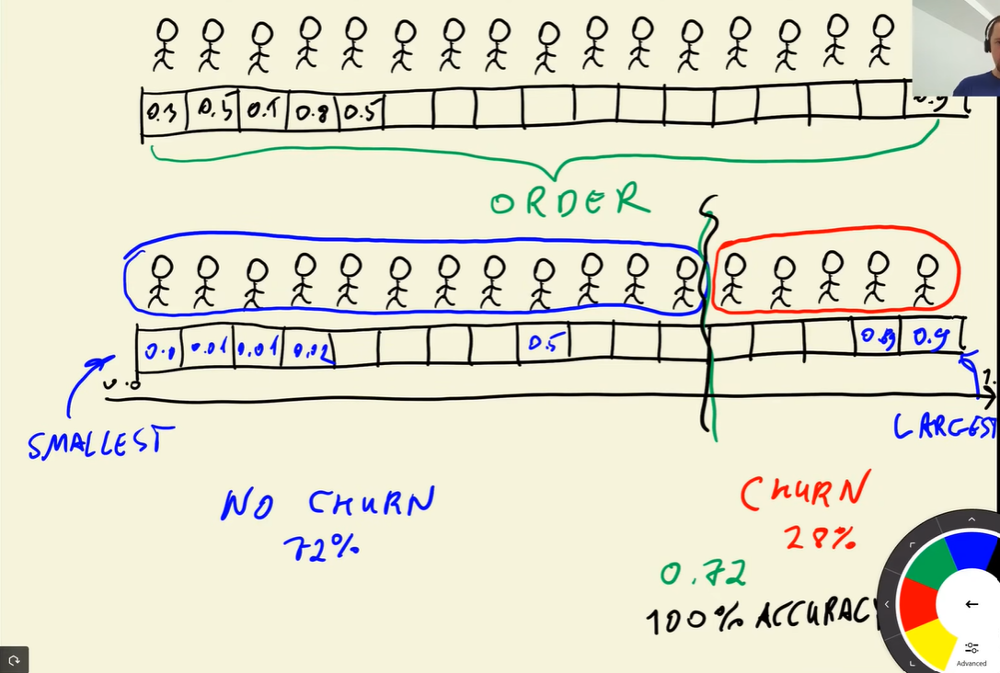

In [52]:
negative_count = (y_val == 0).sum()
negative_count

np.int64(1023)

In [53]:
positive_count = (y_val == 1).sum()
positive_count

np.int64(386)

In [54]:
# Build the ideal model's labels: all the non-churners (0) first, then all the churners (1)
# np.repeat([0, 1], [a, b]) repeats 0 a times and 1 b times
y_ideal = np.repeat([0, 1], [negative_count, positive_count])
y_ideal

array([0, 0, 0, ..., 1, 1, 1], shape=(1409,))

In [55]:
y_ideal_pred = np.linspace(0, 1, len(y_val))
y_ideal_pred

array([0.        , 0.00071023, 0.00142045, ..., 0.99857955, 0.99928977,
       1.        ], shape=(1409,))

In [56]:
# Compute the value for the threshold
1 - y_val.mean()

np.float64(0.7260468417317246)

In [57]:
# Perfect accuracy
((y_ideal_pred >= 0.726) == y_ideal).mean()

np.float64(1.0)

In [58]:
df_ideal = tpr_fpr_dataframe(y_ideal, y_ideal_pred)

df_ideal[::10]

,threshold,tp,fp,fn,tn,tpr,fpr
0,0.0,386,1023,0,0,1.000000,1.000000
10,0.1,386,882,0,141,1.000000,0.862170
20,0.2,386,741,0,282,1.000000,0.724340
30,0.3,386,600,0,423,1.000000,0.586510
40,0.4,386,459,0,564,1.000000,0.448680
50,0.5,386,319,0,704,1.000000,0.311828
60,0.6,386,178,0,845,1.000000,0.173998
70,0.7,386,37,0,986,1.000000,0.036168
80,0.8,282,0,104,1023,0.730570,0.000000
90,0.9,141,0,245,1023,0.365285,0.000000


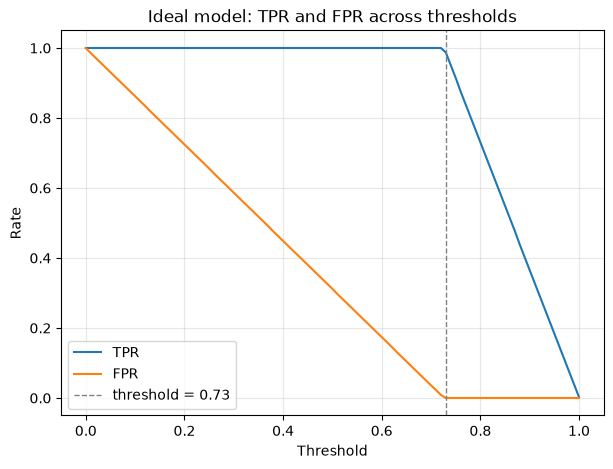

In [59]:
# The perfect cutoff sits where the non-churners end and the churners begin
ideal_threshold = negative_count / len(y_val)

plot_tpr_fpr(df_ideal, ref_threshold=round(ideal_threshold, 2),
             title='Ideal model: TPR and FPR across thresholds')


### Putting everything together

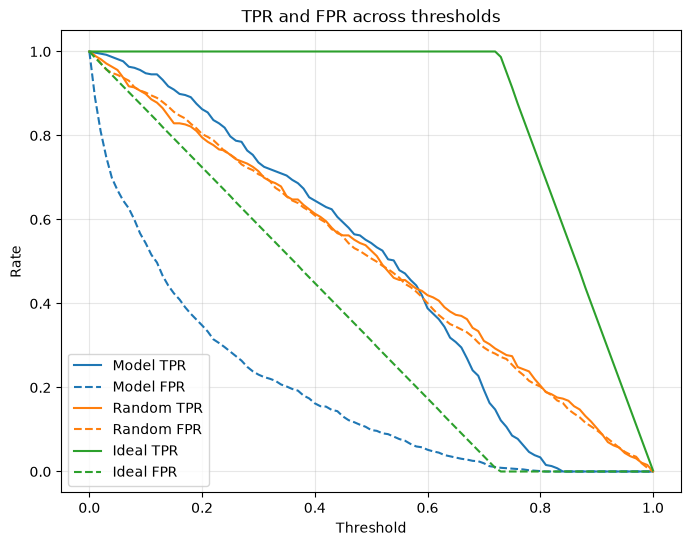

In [60]:
plt.figure(figsize=(8, 6))

plt.plot(df_scores['threshold'], df_scores['tpr'], color='C0', label='Model TPR')
plt.plot(df_scores['threshold'], df_scores['fpr'], color='C0', linestyle='--', label='Model FPR')

plt.plot(df_rand['threshold'], df_rand['tpr'], color='C1', label='Random TPR')
plt.plot(df_rand['threshold'], df_rand['fpr'], color='C1', linestyle='--', label='Random FPR')

plt.plot(df_ideal['threshold'], df_ideal['tpr'], color='C2', label='Ideal TPR')
plt.plot(df_ideal['threshold'], df_ideal['fpr'], color='C2', linestyle='--', label='Ideal FPR')

plt.xlabel('Threshold')
plt.ylabel('Rate')
plt.title('TPR and FPR across thresholds')
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### ROC Curve

Earlier we plotted TPR and FPR against the threshold, which shows how each rate changes as the threshold moves. But it has two drawbacks:

- It needs two lines per model, so comparing several models on one plot gets crowded.
- The threshold is on the x-axis, so the plot says nothing directly about the trade-off we care about: how many churners we catch (TPR) for a given false alarm rate (FPR).

The ROC curve plots FPR against TPR directly, with the threshold only implied by each point's position. This gives one curve per model, so the model, random and ideal curves can sit on the same plot and be compared at a glance. The closer a curve is to the top-left corner, the better the model. It also gives us a single number for each curve, the area under it (AUC), which we cover next.


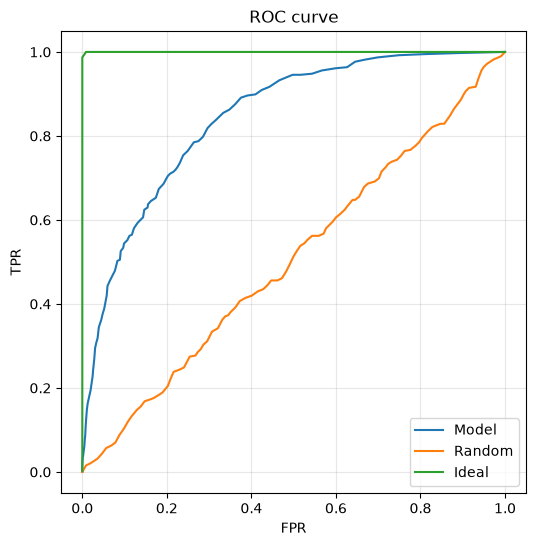

In [61]:
plt.figure(figsize=(6, 6))

plt.plot(df_scores['fpr'], df_scores['tpr'], label='Model')
plt.plot(df_rand['fpr'], df_rand['tpr'], label='Random')
plt.plot(df_ideal['fpr'], df_ideal['tpr'], label='Ideal')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC curve')
plt.grid(alpha=0.3)
plt.legend()
plt.show()


**How to read this chart:**

- Each point on a curve is one threshold. Moving from the top-right to the bottom-left means the threshold is increasing: at the top-right we flag everyone as churn (TPR = 1, FPR = 1), and at the bottom-left we flag no one (TPR = 0, FPR = 0).
- **Random (orange):** roughly the diagonal. The model has no signal, so TPR ≈ FPR at every threshold. Every churner we catch costs us an equal share of false alarms.
- **Ideal (green):** goes straight up the left edge and then across the top. There is a threshold where we catch every churner (TPR = 1) with no false alarms (FPR = 0).
- **Our model (blue):** sits between the two. It's well above the diagonal, so it has real signal, but below the ideal curve, so it isn't perfect. For example, at an FPR of about 0.2 it catches about 70% of churners.

The closer a curve is to the top-left corner, the better the model. The area under each curve, the ROC AUC, turns this into a single number: 0.5 for random, 1.0 for ideal, and our model's value falls in between.


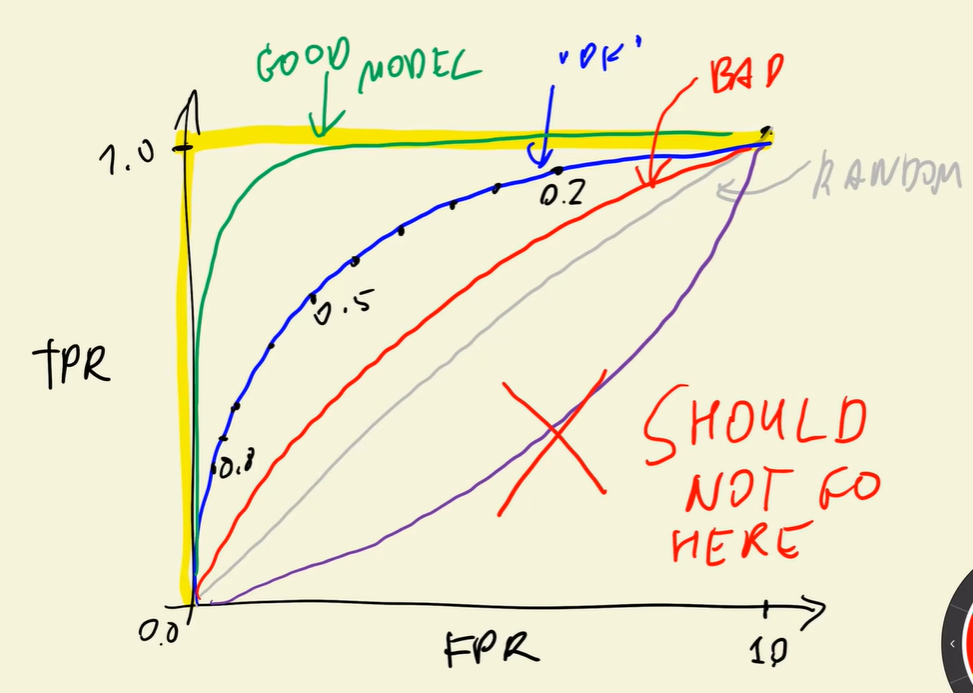

### Plotting ROC curves with sklearn

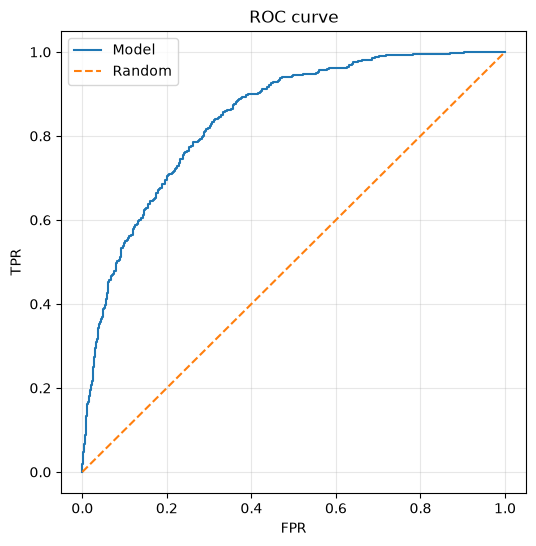

In [62]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)


plt.figure(figsize=(6, 6))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC curve')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## ROC AUC

### Concepts

The ROC curve is a plot, but it's hard to compare models by eye. **ROC AUC** (area under the ROC curve) boils the curve down to a single number between 0 and 1:

- **1.0:** perfect separation of churners from non-churners (the ideal model).
- **0.5:** no better than random guessing (the diagonal).
- **In between:** the closer to 1, the better the model separates the two classes.

AUC is threshold-free because it summarizes the model across all thresholds, so it's useful for comparing models. It also has an intuitive meaning: it's the probability that a randomly chosen churner gets a higher score than a randomly chosen non-churner.


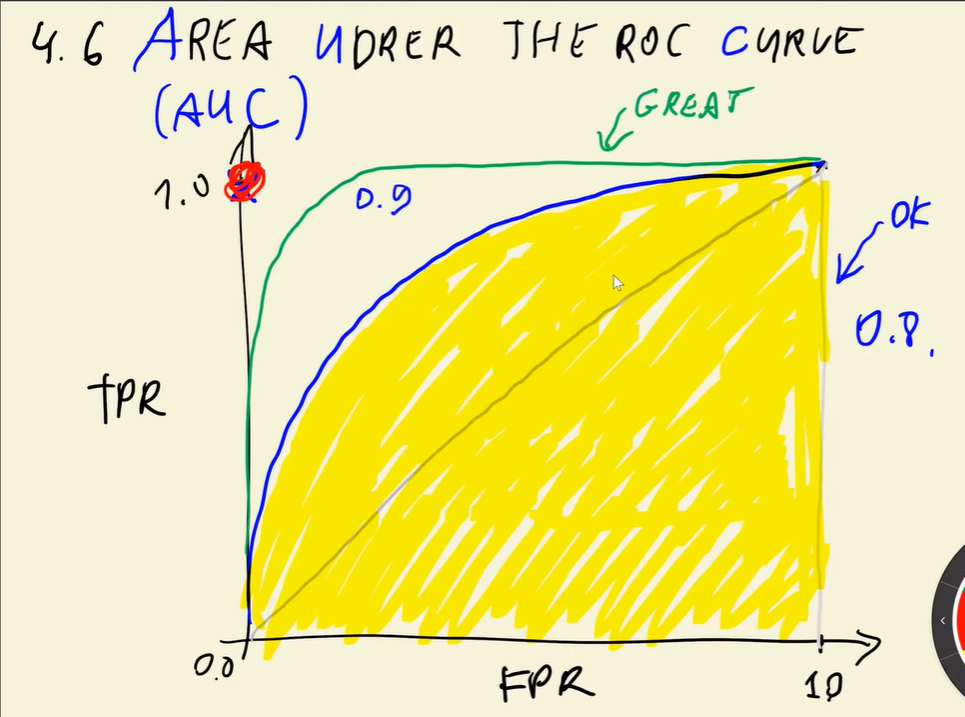

Two baselines:

- **0.5 AUC** - Worst case

- **1.0 AUC** - Best case

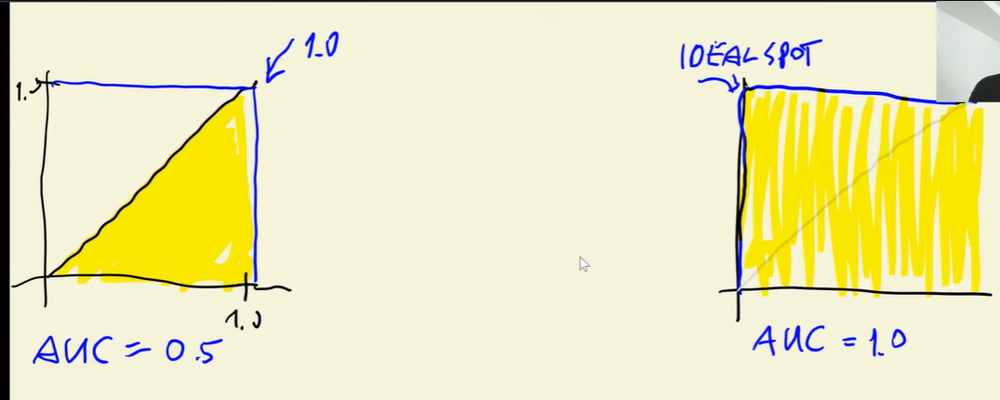

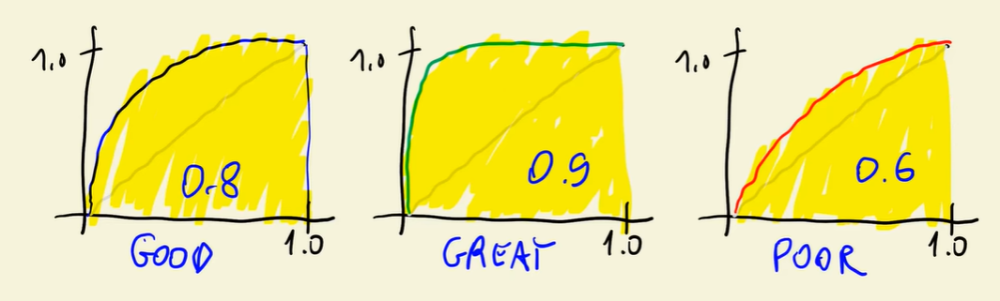

### Implementation (`auc`)

In [63]:
from sklearn.metrics import auc

# FPR and TPR were computed using sklearn from previous lesson
auc(fpr, tpr)

0.8438454408703447

In [64]:
# AUC of ideal model
auc(df_ideal.fpr, df_ideal.tpr)

0.9999430203759136

In [65]:
# AUC of random model
auc(df_rand.fpr, df_rand.tpr)

0.5061462021181226

### Implementation (`roc_auc_score`)

In [66]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.8438454408703447

### How we calculate AUC

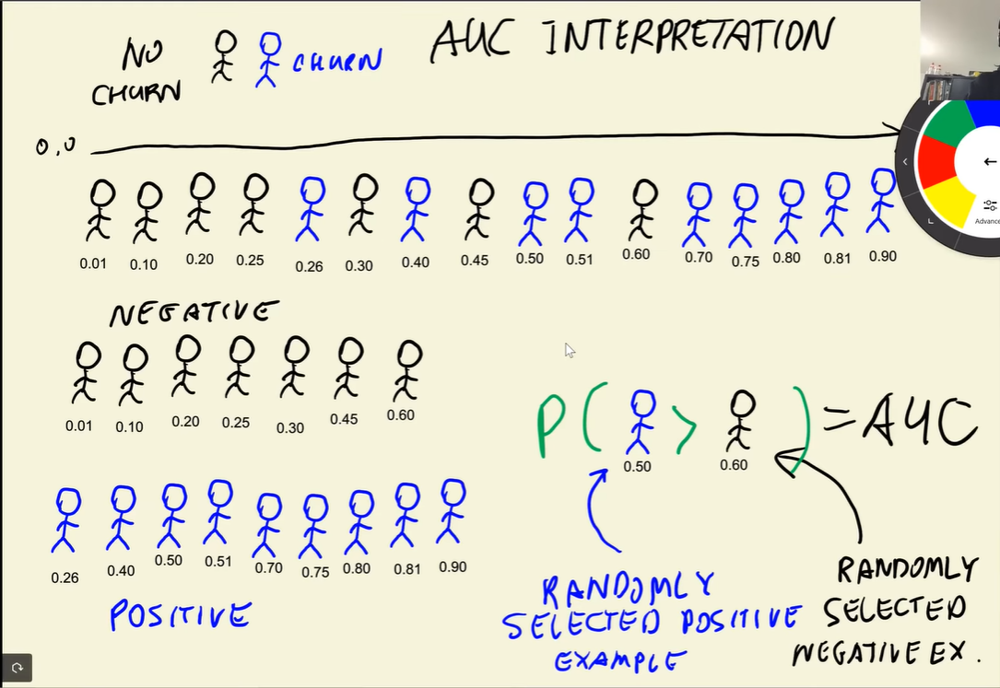

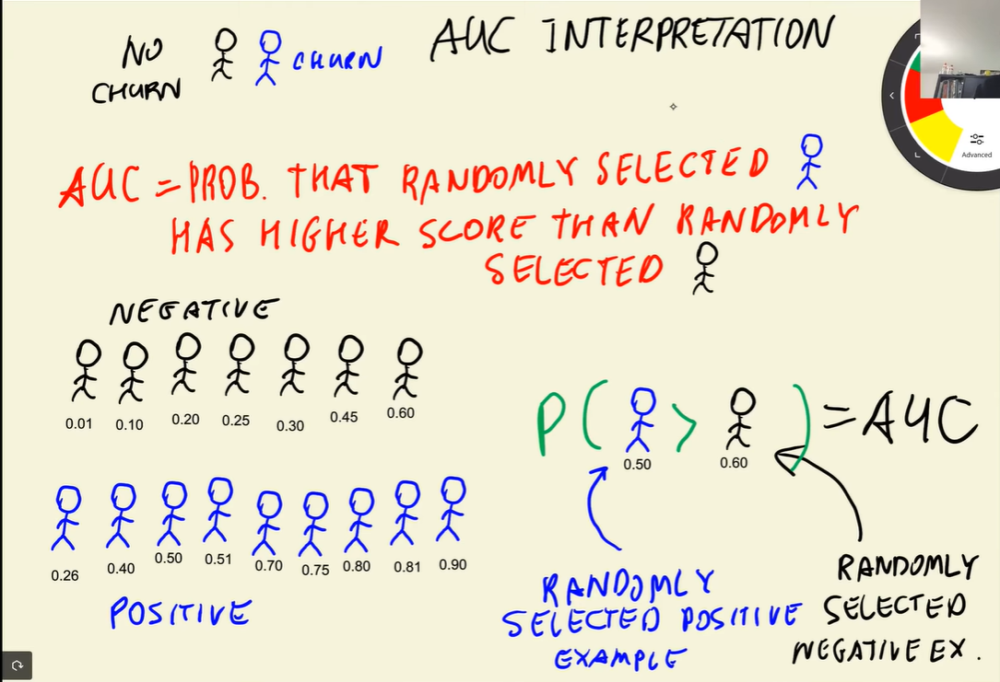

In [67]:
negatives = y_pred[y_val == 0]
negatives[:10]

array([0.00900149, 0.20409034, 0.21172505, 0.21331459, 0.20517997,
       0.02778426, 0.00296488, 0.04159713, 0.50045446, 0.08014638])

In [68]:
positives = y_pred[y_val == 1]
positives[:10]

array([0.54275111, 0.58189826, 0.46144658, 0.73898105, 0.0659918 ,
       0.69134472, 0.24727729, 0.69616359, 0.21158972, 0.66471698])

Plain Python implementation

In [69]:
import random

n = 1000000
success = 0

for i in range(n):

    positive_idx = random.randint(0, len(positives) - 1)
    negative_idx = random.randint(0, len(negatives) - 1)

    if positives[positive_idx] > negatives[negative_idx]:
        success += 1

print(f'AUC: {success / n}')

AUC: 0.843775


NumPy implementation (faster)

In [70]:
np.random.seed(RANDOM_SEED)

positive_idx = np.random.randint(0, len(positives), size=n)
negative_idx = np.random.randint(0, len(negatives), size=n)

auc = (positives[positive_idx] > negatives[negative_idx]).mean()
print(f'AUC: {auc}')

AUC: 0.843942


## Cross-Validation

### K-fold cross validation

In previous lessons, we always had a fixed train, val, and test sets

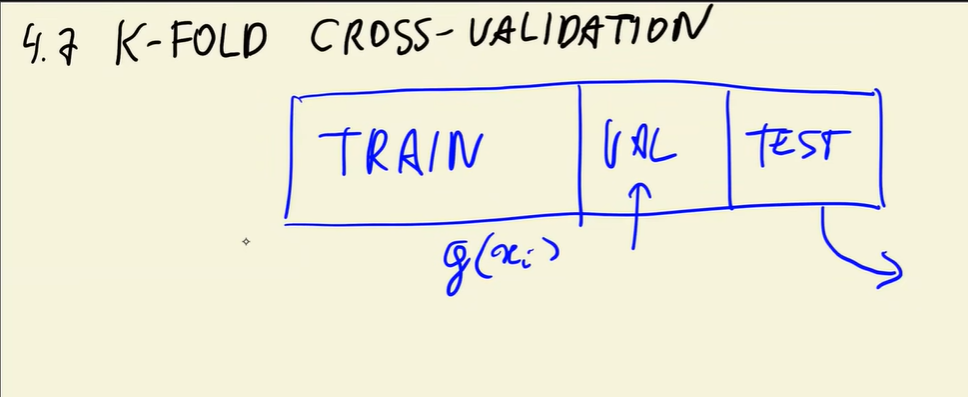

In **K-fold Cross-Validation**, we still hold out the test set, but we split the training set into K folds. 

We train K times, each time using a different fold as the validation set and the remaining folds for training. 

Averaging the K scores gives a more reliable estimate of model quality than a single train/validation split.

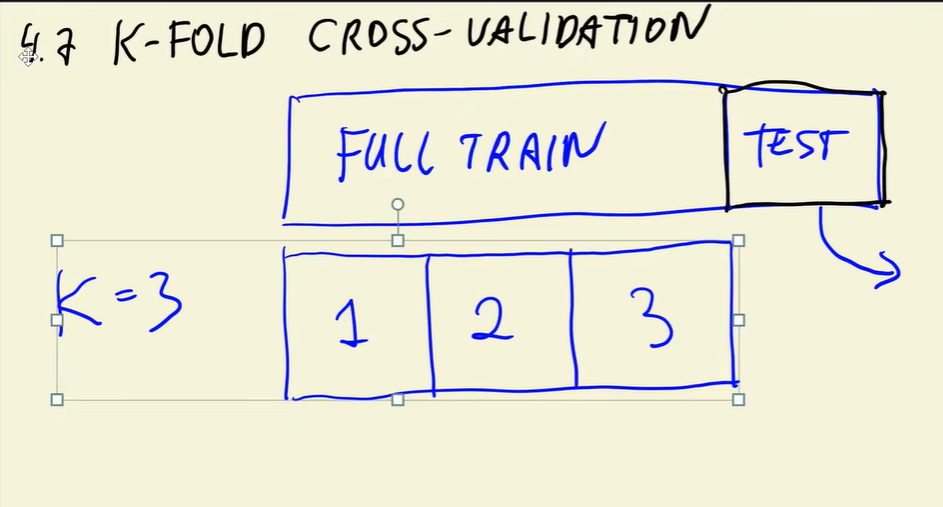

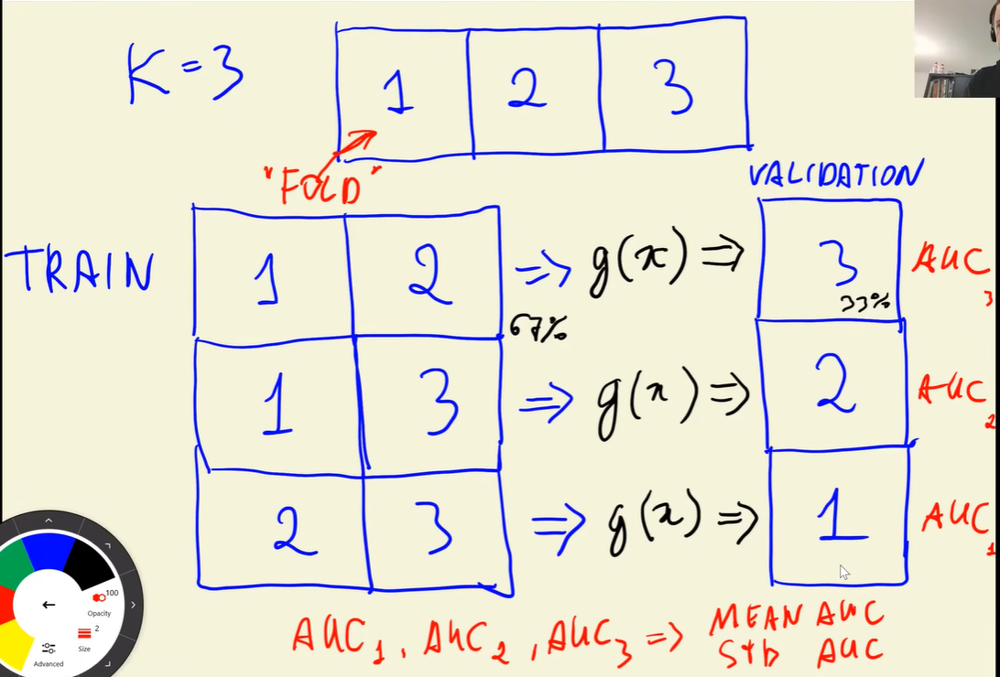

### Define train and predict functions

In [71]:
def train(df, y_train, C=1.0):

    dicts = df[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(random_state=RANDOM_SEED, C=C, max_iter=100000)

    model.fit(X_train, y_train)

    return dv, model

In [72]:
dv, model = train(df_train, y_train)

In [73]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [74]:
y_pred = predict(df_val, dv, model)
y_pred

array([0.00666591, 0.2048263 , 0.21770395, ..., 0.15156007, 0.78870418,
       0.81191834], shape=(1409,))

### Implement in sklearn

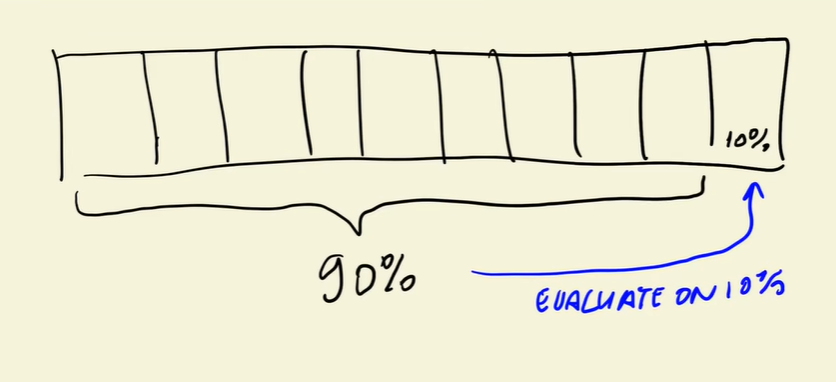

In [75]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)
kfold

KFold(n_splits=10, random_state=1, shuffle=True)

In [76]:
from tqdm.auto import tqdm


scores = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train)):

    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['churn'].values
    y_val = df_val['churn'].values

    dv, model = train(df_train, y_train)

    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)


0it [00:00, ?it/s]

In [77]:
scores

[0.8497050077127364,
 0.842342202970297,
 0.8583957610085876,
 0.8332400625462926,
 0.824643300248139,
 0.8410589410589411,
 0.8430804298274178,
 0.8253399746995572,
 0.8459759893285905,
 0.8610634936640784]

In [78]:
print(f'{np.mean(scores).round(3)} +/- {np.std(scores).round(3)}')

0.842 +/- 0.012


### Hyperparameter tuning

In [82]:
n_splits = 5
C = [0.001, 0.01, 0.1, 0.5, 1, 5, 10]

for c in tqdm(C):

    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_SEED)

    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):

        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['churn'].values
        y_val = df_val['churn'].values

        dv, model = train(df_train, y_train, C=c)

        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (c, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009
C=0.01 0.840 +- 0.008
C=0.1 0.842 +- 0.007
C=0.5 0.842 +- 0.007
C=1 0.842 +- 0.007
C=5 0.842 +- 0.007
C=10 0.842 +- 0.007


### Train final model

In [83]:
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8583517501381259